In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import jv

font = {"size": 26}

plt.rc("font", **font)
plt.rcParams["figure.figsize"] = (20, 9)
plt.rcParams["lines.linewidth"] = 3
plt.rcParams["legend.fontsize"] = 20

# The Discrete Hankel Transform

In [2]:
def DHTarrays(N, R, ell):
    Zeroes = np.genfromtxt("BesselZeroes" + str(ell) + ".csv")
    r = R * Zeroes[:N] / Zeroes[N - 1]
    k = Zeroes[:N] / R
    return np.array([r, k])

def DHTtransformMatrix(N, R, ell):
    Zeroes = np.genfromtxt("BesselZeroes" + str(ell) + ".csv")
    alpha = Zeroes[:N]
    kR = alpha[N - 1]
    kmax = kR / R
    T = (
        jv(ell, np.outer(alpha, alpha) / kR)
        / np.outer(abs(jv(ell + 1, alpha)), abs(jv(ell + 1, alpha)))
        / kR
    )
    # print(T)
    A = abs(jv(ell + 1, alpha))
    T_R2K = 4.0 * np.pi * (R / kmax) * T * A[:, None] / A[None, :]
    T_K2R = (1 / np.pi) * (kmax / R) * T * A[:, None] / A[None, :]

    return T_R2K, T_K2R

# Propagation

Propagates incident beam `phi_I` over `z` after reflecting from the mirror `zm`using DHT

In [3]:
def forward_propagation(k, phi_I, T_R2K, T_K2R, z, zm, wavelength):
    k0 = 2 * np.pi / wavelength
    phi_R0 = phi_I * np.exp(-2j * k0 * zm) #reflected profile from mirror

    # Hankel transform the field through multiplying by the appropriate transform matrix
    FT = T_R2K @ phi_R0
    # Propagate phi_R0 over z through multiplying phi_R0 by the diffractive phase:
    FT = FT * np.exp(-1j * k**2 / (2 * k0) * z[:, np.newaxis])
    # Inverse Hankel transform 𝐸̃ from 𝑘𝑟-space to 𝑟-space through multiplying by the inverse transform matrix
    fT = T_K2R @ (FT.T)

    return fT

# Sagitta Function
$s_f(r)=\frac{R^2}{4L}\ln\left[1+\frac{L}{f_0}\left(\frac{r}{R}\right)^2\right]$
or Taylor Expanded:
$s_f(r)\approx\frac{r^2}{4f_0}\left( 1-\frac{L}{f_0}(\frac{r}{R})^2\right)$

In [4]:
def create_axiparabola(r,R,L,f0,taylor=True):
    if taylor:
        sag = r**2/(4*f0)*(1-L/(2*f0)*(r/R)**2)
    else:
        sag = R**2/(4*L)*np.log(1+L/f0 *(r/R)**2)
    return sag

# Parameters

In [5]:
f = 0.5  # focal length of lens
fn=20
R = f/(2*fn)
ell = 0  # order of Bessel J function
wl=1e-6
k0 = 2 * np.pi / wl  # k=2*pi/wavelength
# L=[0.0, 1e-4, 1e-3, 1e-2, 5e-2]
L=10e-2
# zR = np.pi * w0**2 / wl  # Initial rayleigh length
# print(zR)
# print(wl*f**2/(np.pi*R**2))
nr=2000
wf = 2 / np.pi *fn * wl
zR=wl*f**2/(np.pi*R**2)

print(R)
print(fn)
print(zR/1e-6)
print(4*fn**2*wl/np.pi/1e-6)
print(R/nr)
print(wf/1e-6)
print(R/nr < wf)

0.0125
20
509.2958178940651
509.2958178940651
6.25e-06
12.732395447351628
True


In [6]:
[r, k] = DHTarrays(nr, R, ell)
[T_R2K, T_K2R] = DHTtransformMatrix(nr, R, ell)
phi_I=1j*np.exp(-((r / (0.9*R)) ** 64))


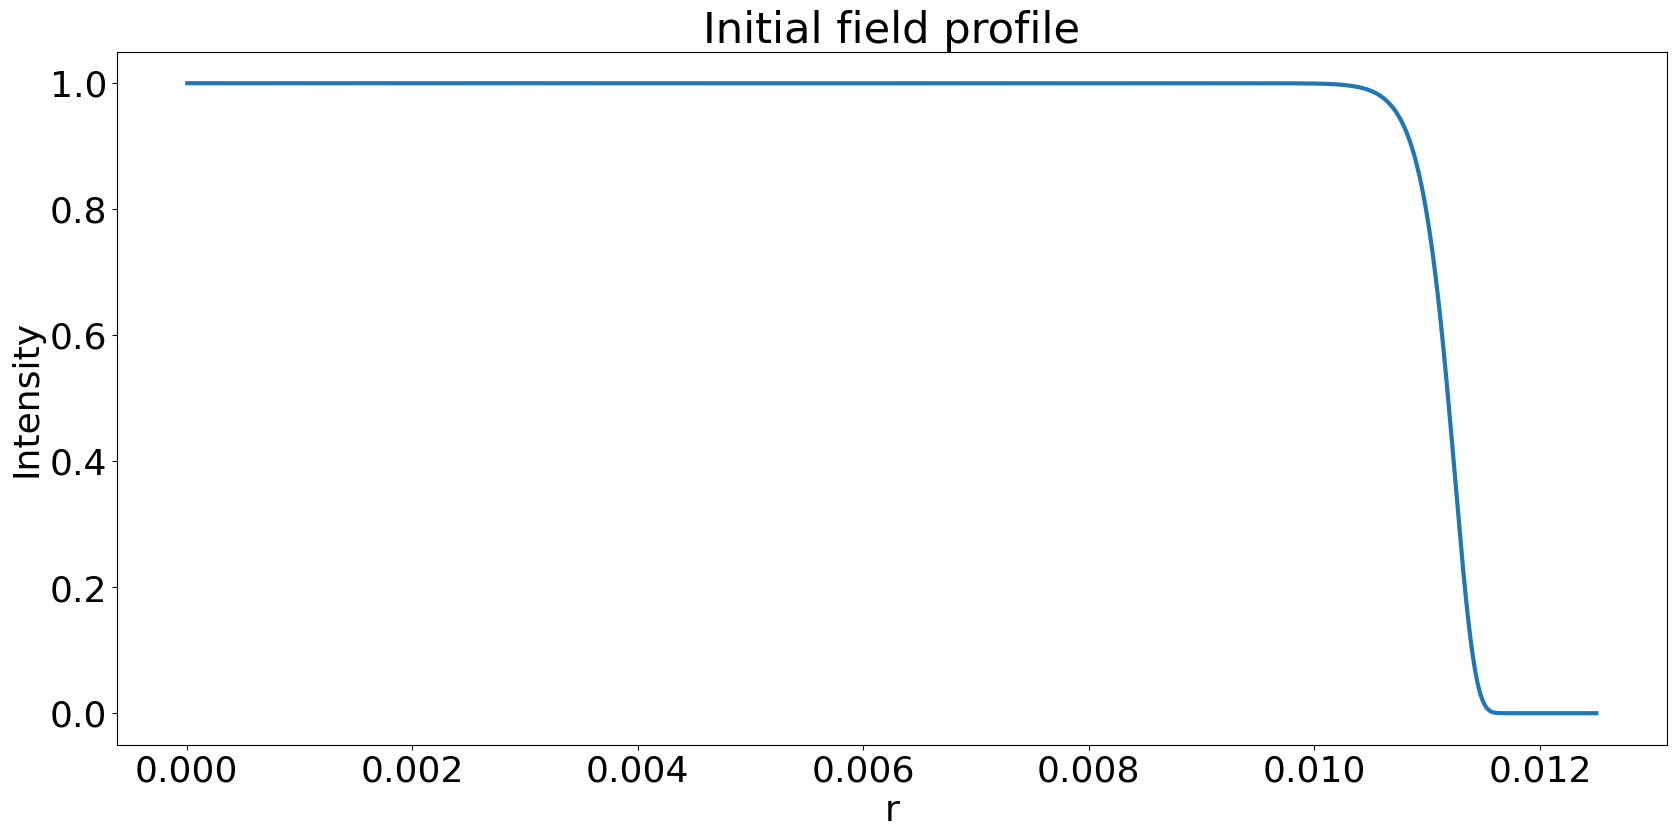

In [7]:
#plot phi_I
plt.figure()
plt.plot(r, np.abs(phi_I))
plt.xlabel("r")
plt.ylabel("Intensity")
plt.title("Initial field profile")
plt.show()


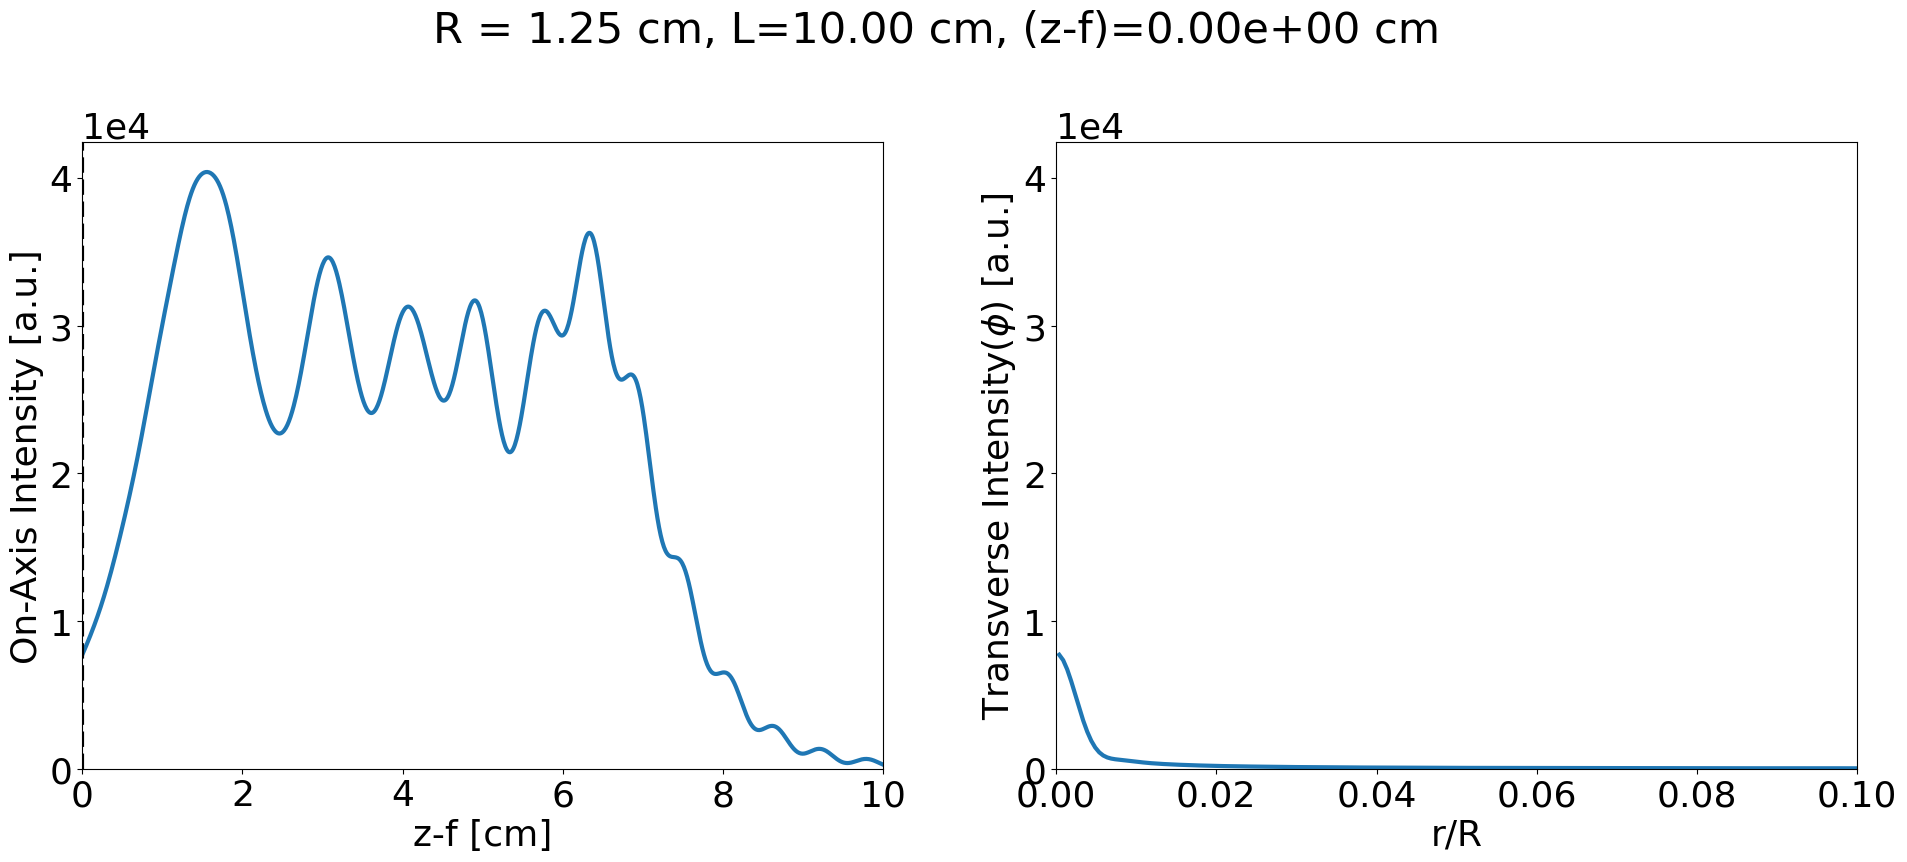

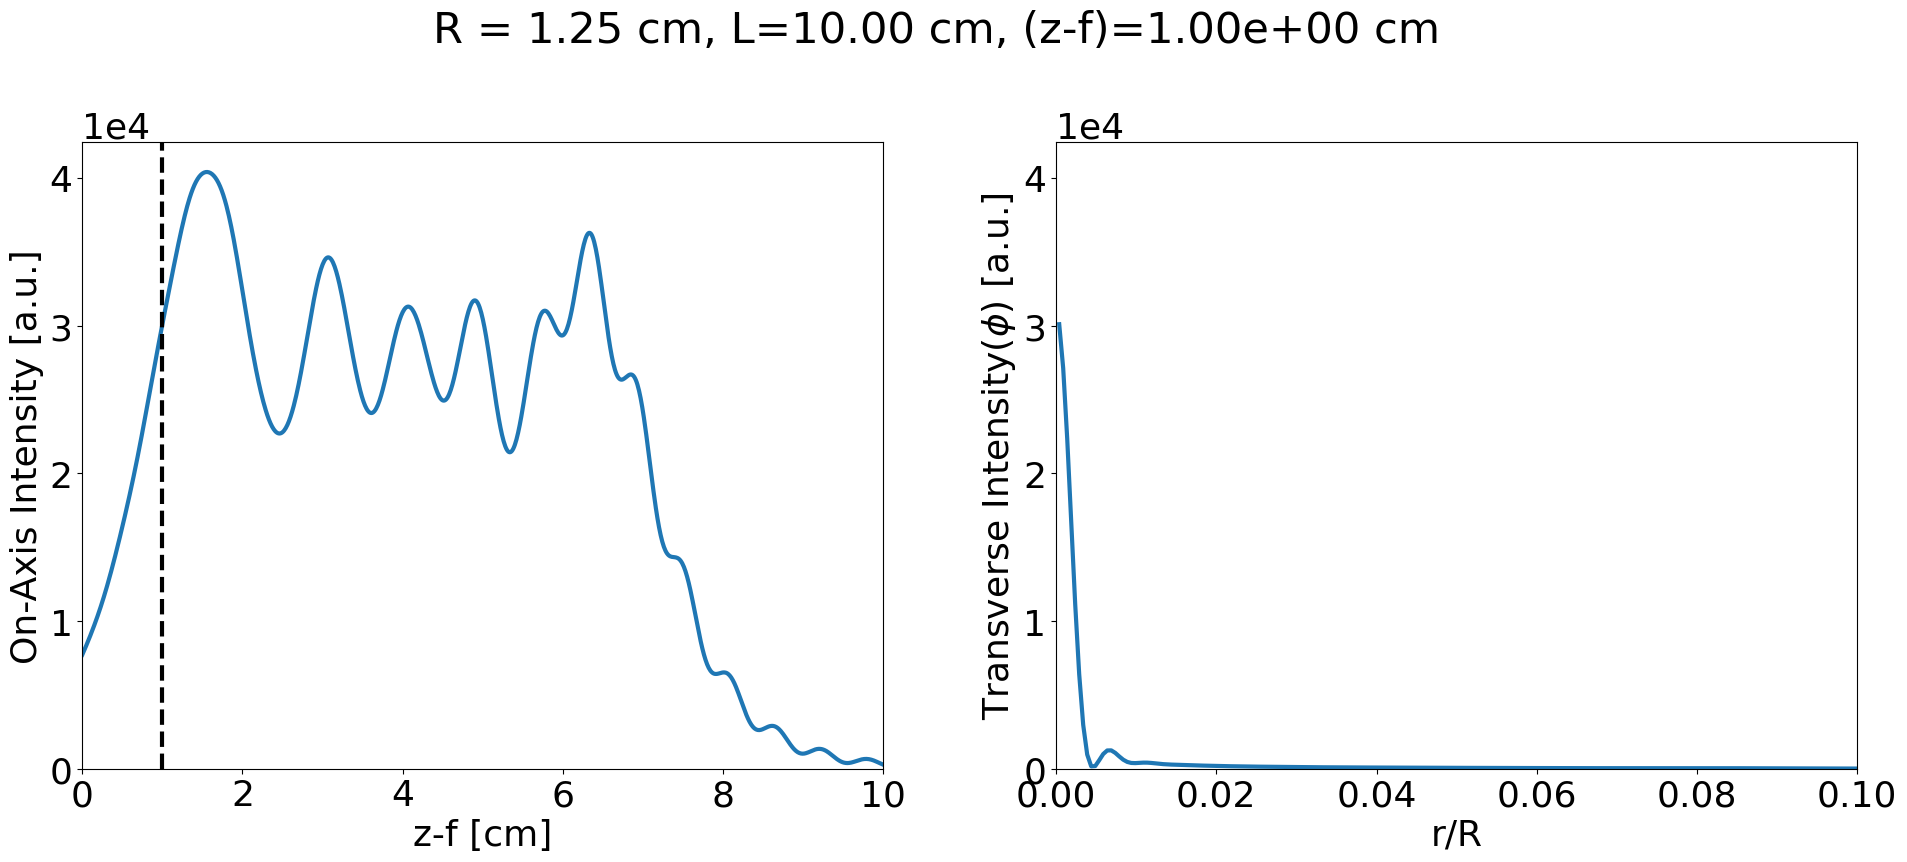

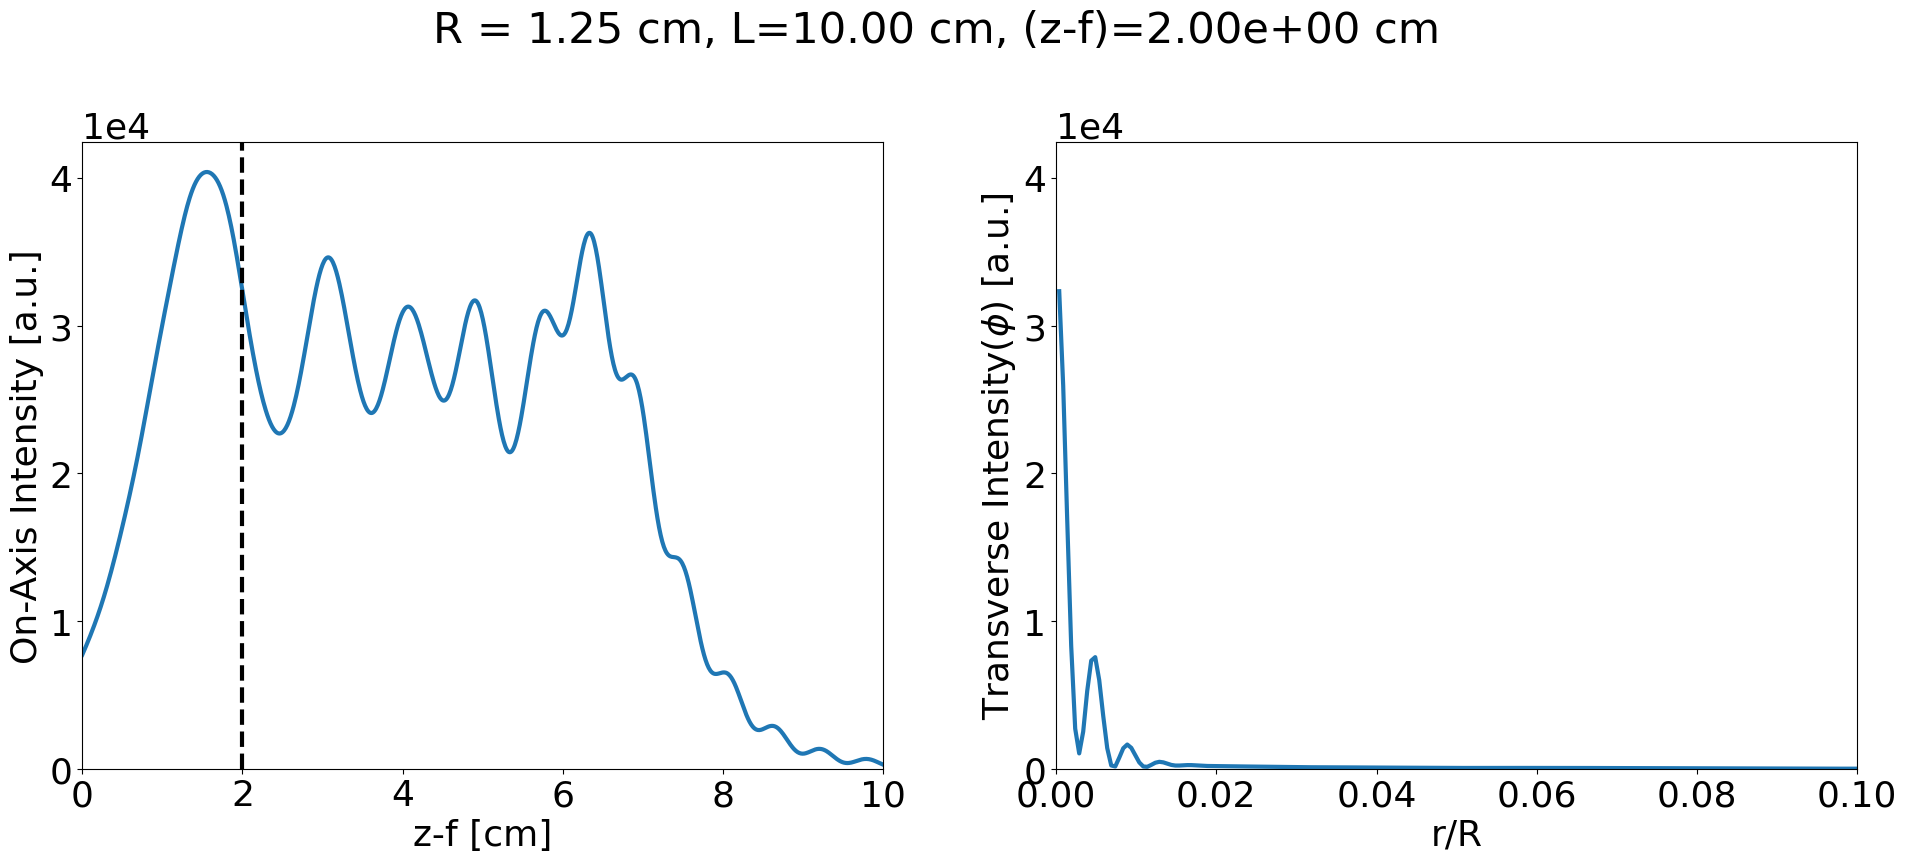

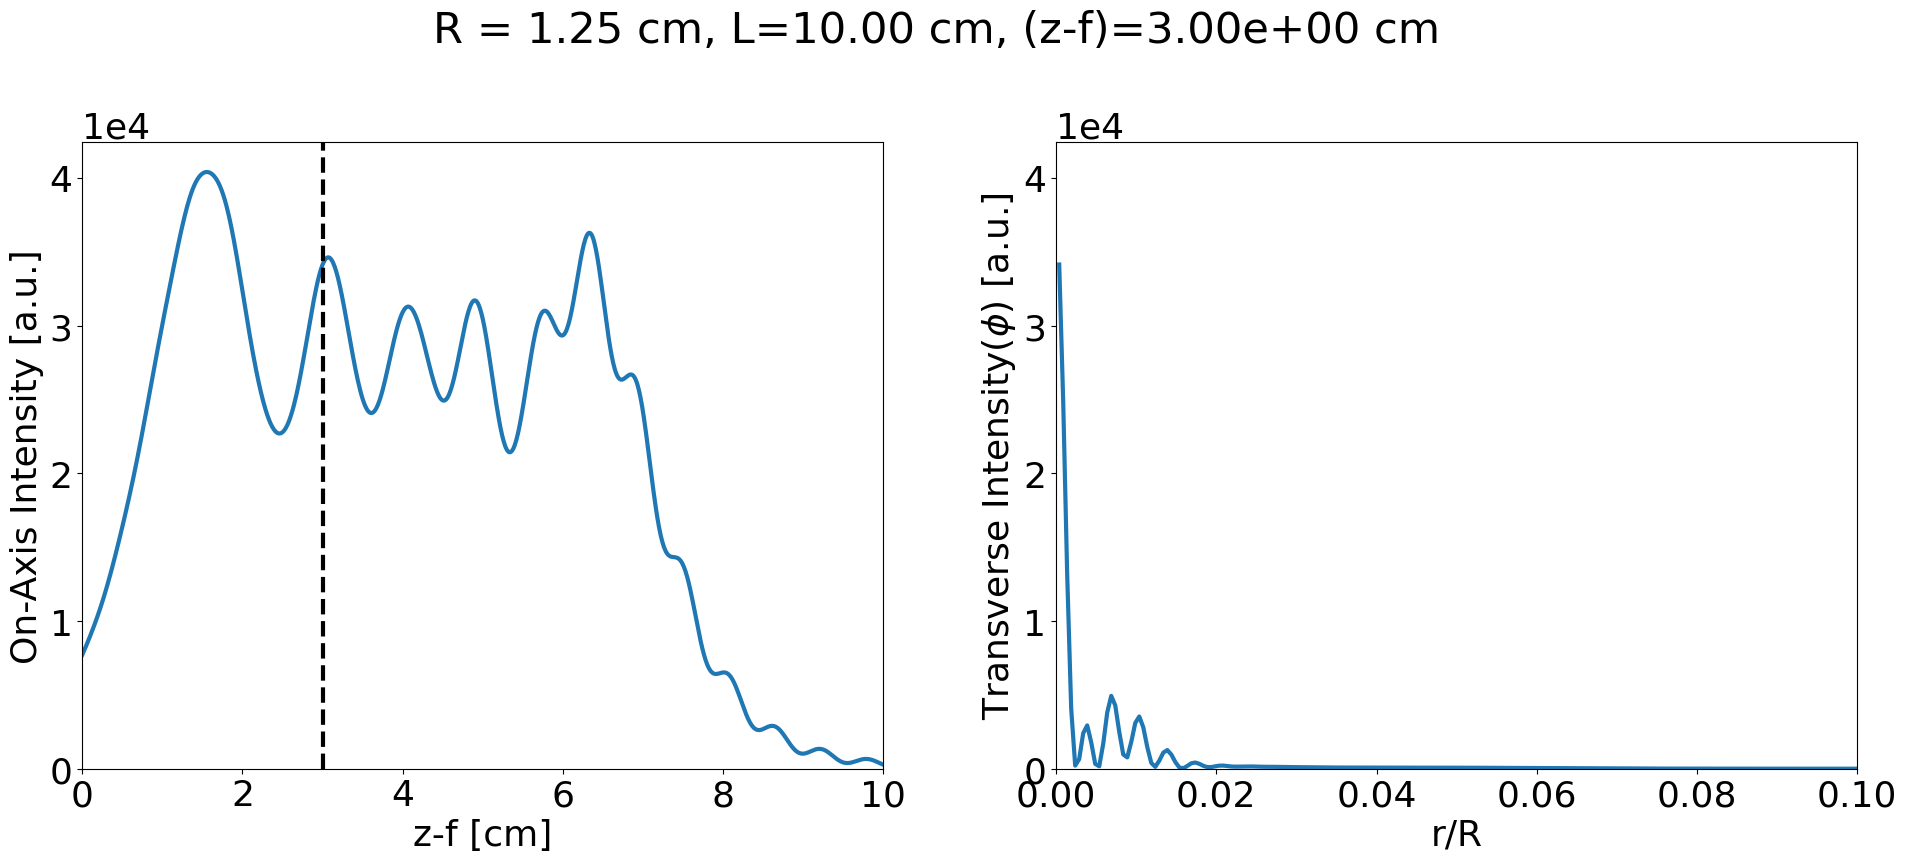

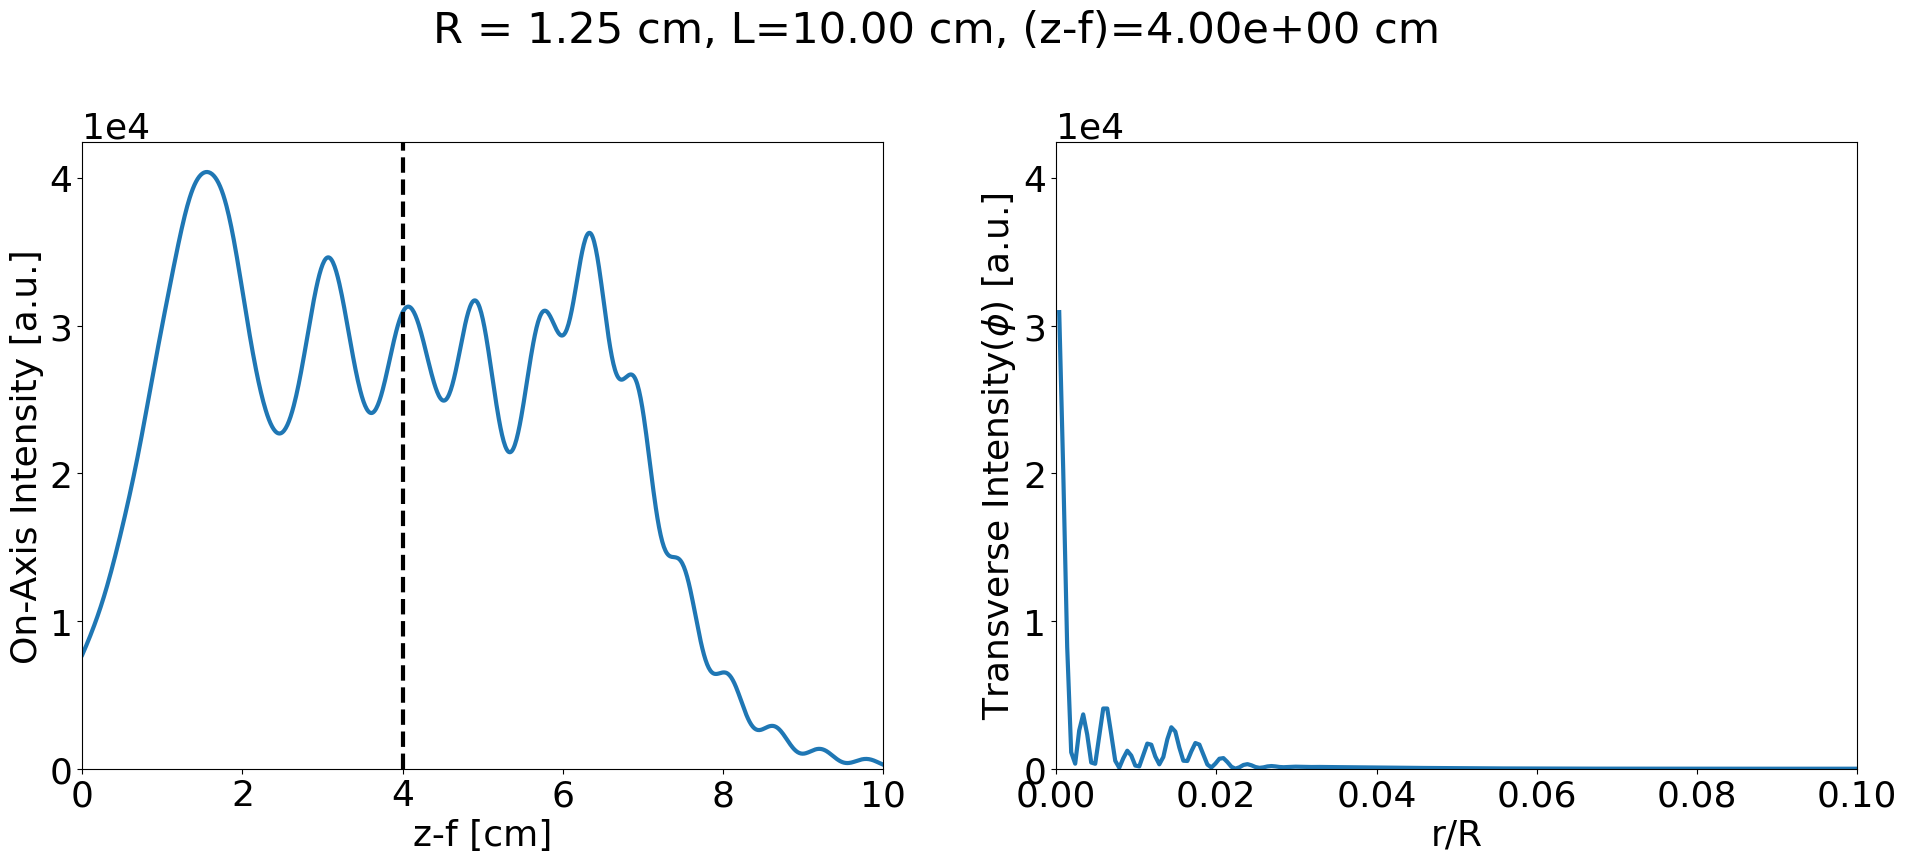

In [8]:
for i in range(5):
    fig, ax = plt.subplots(1, 2, sharey=True)

    # Initial field
    z_mir=create_axiparabola(r,R,L,f,taylor=False)
    z=np.linspace(f,f+L,1001)

    ftf=forward_propagation(k, phi_I, T_R2K, T_K2R, z, z_mir, wl)

    #subplot side by side
    ax[0].plot((z-f)*100, np.abs(ftf[0,:]**2))
    # fl=len(z)//2+i*40
    fl=i*100
    # print(z[fl])
    ax[1].plot(r/R, np.abs(ftf[:, fl])**2)
    #plot marker on left that corresponds to the right plot
    ax[0].axvline(x=(z[fl]-f)*100, color='black', linestyle='--')

    ax[0].set_xlabel("z-f [cm]")
    ax[0].set_ylabel("On-Axis Intensity [a.u.]")
    ax[0].set_xlim([0, L*100])
    ax[0].set_ylim(ymin=0)
    # scientific notation for y axis 
    ax[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    # show numbers on second y axis
    ax[0].yaxis.get_offset_text().set_visible(True)    

    ax[1].set_xlim([0, 0.1])
    ax[1].set_xlabel("r/R")
    ax[1].set_ylabel(r"Transverse Intensity($\phi$) [a.u.]")   
    fig.suptitle("R = %.2f cm, L=%.2f cm, (z-f)=%.2e cm" % (R*100, L*100, (z[fl]-f)*100)) 
    ax[1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax[1].yaxis.set_tick_params(labelleft=True)
    #keep same ylim  all plots
    # ax[1].set_ylim([np.min(np.abs(ftf)**2), np.max(np.abs(ftf)**2)])

    # plt.legend()
    plt.tight_layout()
    plt.savefig("L-%.2fcm_fn-%d_%d.png" % (L*100, fn, i))
# plt.show()
# plt.savefig("L-1cm_fn-5.png")

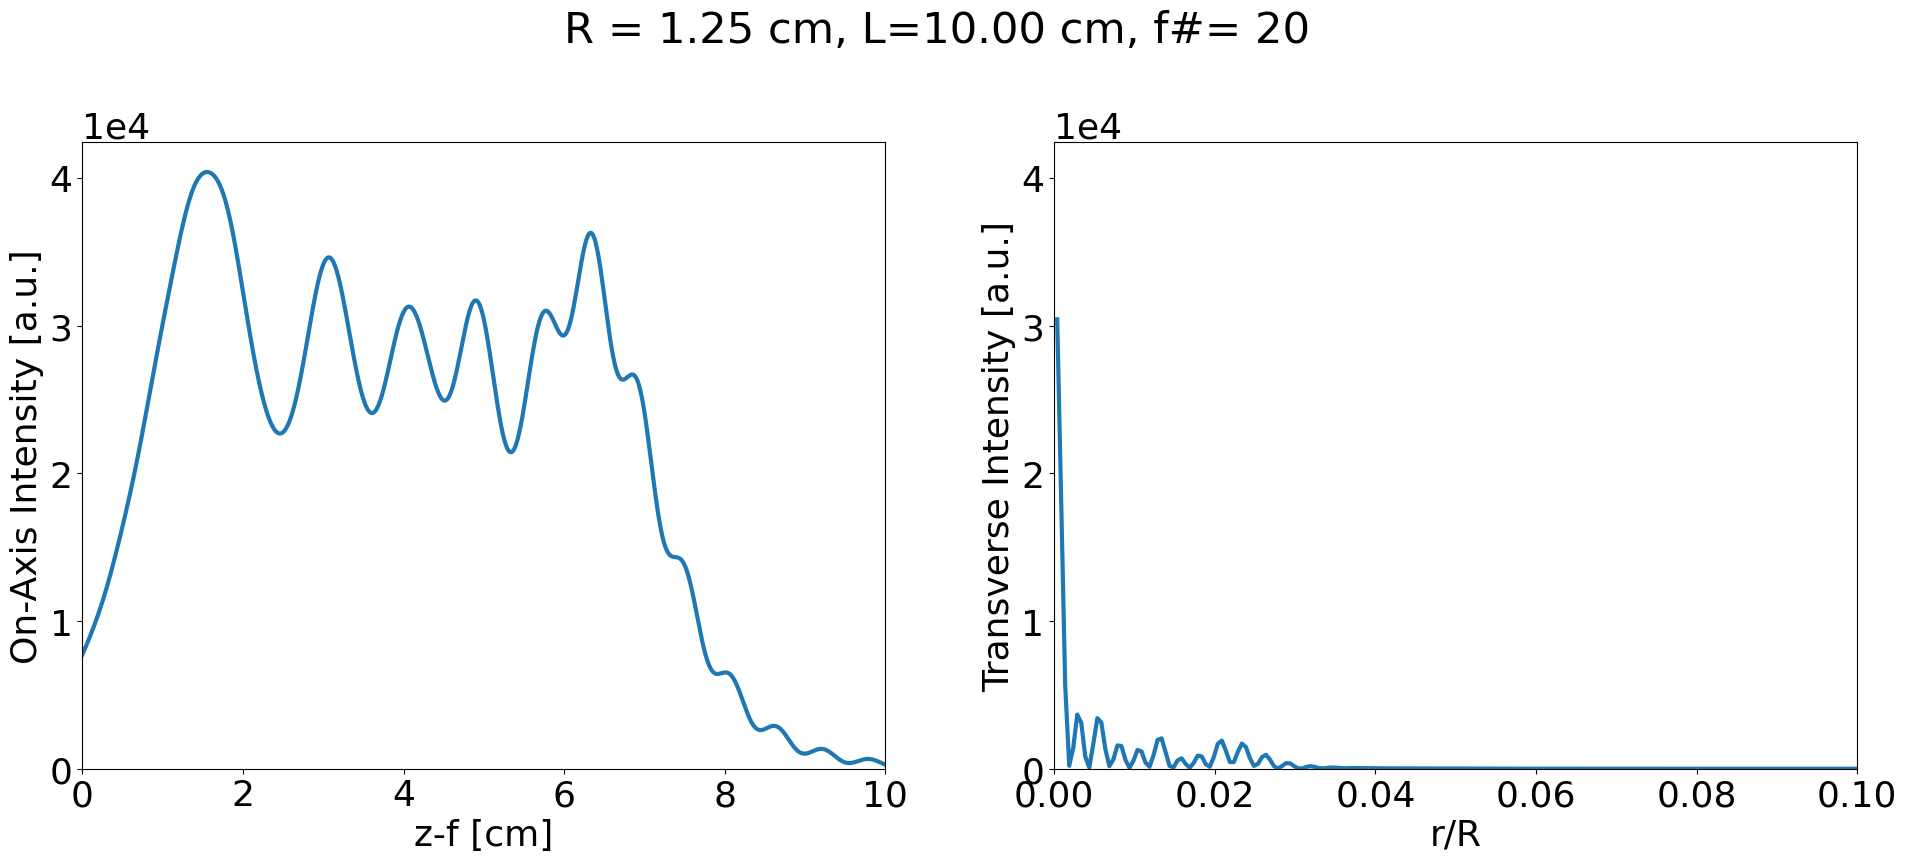

In [17]:
fig, ax = plt.subplots(1, 2, sharey=True)

z_mir=create_axiparabola(r,R,L,f, taylor=False)
z=np.linspace(f,f+L,1001)

ftf=forward_propagation(k, phi_I, T_R2K, T_K2R, z, z_mir, wl)

#subplot side by side
ax[0].plot((z-f)*100, np.abs(ftf[0,:]**2))
ax[1].plot(r/R, np.abs(ftf[:, len(z)//2]**2), label="L=%.2e cm" % (L*100))

ax[0].set_xlabel("z-f [cm]")
ax[0].set_ylabel("On-Axis Intensity [a.u.]")
ax[0].set_xlim([0, 10])
ax[0].set_ylim(ymin=0)
# scientific notation for y axis 
ax[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
ax[1].set_xlim([0, 0.1])
ax[1].set_xlabel("r/R")
ax[1].set_ylabel(r"Transverse Intensity [a.u.]")
ax[1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
ax[1].yaxis.set_tick_params(labelleft=True)
# plt.legend()
fig.suptitle("R = %.2f cm, L=%.2f cm, f#= %d" % (R*100, L*100, fn) )

plt.tight_layout()
plt.savefig("L-%.2fcm_fn-%d.png" % (L*100, fn))
# plt.show()
# plt.savefig("L-1cm_fn-5.png")

In [13]:
# compare with taylor true and false
z_mir=create_axiparabola(r,R,L,f)
z_mir_og=create_axiparabola(r,R,L,f,taylor=False)

z=np.linspace(f-0.1,f+0.15,1001)

ftf=forward_propagation(k, phi_I, T_R2K, T_K2R, z, z_mir, wl)
ftf_og=forward_propagation(k, phi_I, T_R2K, T_K2R, z, z_mir_og, wl)

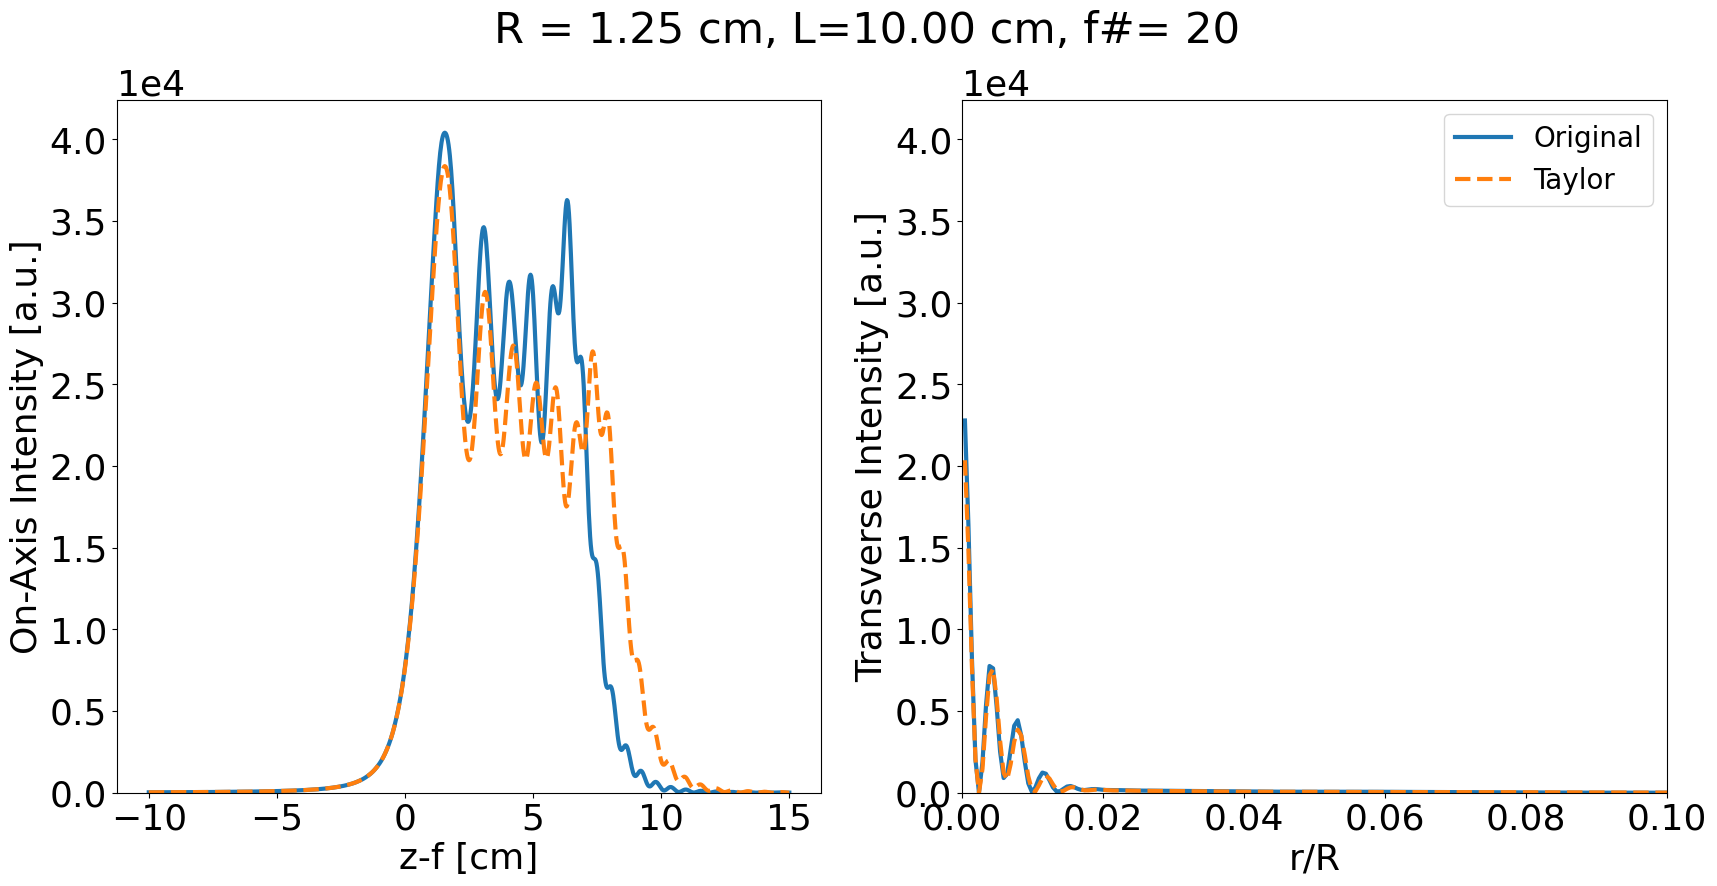

In [14]:
fig, ax = plt.subplots(1, 2, sharey=True)
ax[0].plot((z-f)*100, np.abs(ftf_og[0,:]**2), label="Original")
ax[0].plot((z-f)*100, np.abs(ftf[0,:]**2), label="Taylor", linestyle='--')
ax[1].plot(r/R, np.abs(ftf_og[:, len(z)//2]**2), label="Original")

ax[1].plot(r/R, np.abs(ftf[:, len(z)//2]**2), label="Taylor", linestyle='--')

ax[0].set_xlabel("z-f [cm]")
ax[0].set_ylabel("On-Axis Intensity [a.u.]")
# ax[0].set_xlim([-2.5, 7.5])
ax[0].set_ylim(ymin=0)
# scientific notation for y axis

ax[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

# share y axis


ax[1].set_xlim([0, 0.1])
ax[1].set_xlabel("r/R")
ax[1].set_ylabel(r"Transverse Intensity [a.u.]")
ax[1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
ax[1].yaxis.set_tick_params(labelleft=True)
plt.legend()
fig.suptitle("R = %.2f cm, L=%.2f cm, f#= %d" % (R*100, L*100, fn))
plt.savefig('comparing_original_taylor_fn%d'%(fn))